In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("housing.csv")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully
Dataset shape: (545, 13)


,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


In [2]:
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

print("\nMissing values in each column:")
print(df.isnull().sum())

Column names:
['price', 'area', 'bedrooms', 'bathrooms', 'stories', 'mainroad', 'guestroom', 'basement', 'hotwaterheating', 'airconditioning', 'parking', 'prefarea', 'furnishingstatus']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7

In [3]:
# Convert categorical text columns into numeric columns
df_encoded = pd.get_dummies(
    df,
    columns=[
        "mainroad",
        "guestroom",
        "basement",
        "hotwaterheating",
        "airconditioning",
        "prefarea",
        "furnishingstatus"
    ],
    drop_first=True,
    dtype=int
)

print("Original dataset shape:", df.shape)
print("Encoded dataset shape:", df_encoded.shape)

df_encoded.head()

Original dataset shape: (545, 13)
Encoded dataset shape: (545, 14)


,price,area,bedrooms,bathrooms,stories,parking,mainroad_yes,guestroom_yes,basement_yes,hotwaterheating_yes,airconditioning_yes,prefarea_yes,furnishingstatus_semi-furnished,furnishingstatus_unfurnished
0,13300000,7420,4,2,3,2,1,0,0,0,1,1,0,0
1,12250000,8960,4,4,4,3,1,0,0,0,1,0,0,0
2,12250000,9960,3,2,2,2,1,0,1,0,0,1,1,0
3,12215000,7500,4,2,2,3,1,0,1,0,1,1,0,0
4,11410000,7420,4,1,2,2,1,1,1,0,1,0,0,0


In [4]:
from sklearn.model_selection import train_test_split

# Separate features and target
X = df_encoded.drop("price", axis=1)
y = df_encoded["price"]

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (436, 13)
Testing features: (109, 13)
Training target: (436,)
Testing target: (109,)


In [5]:
from sklearn.linear_model import LinearRegression

# Create the model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [6]:
# Predict prices for the test dataset
y_pred = model.predict(X_test)

# Compare actual and predicted prices
comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred.round(0).astype(int)
})

comparison.head(10)

,Actual Price,Predicted Price
0,4060000,5164654
1,6650000,7224722
2,3710000,3109863
3,6440000,4612075
4,2800000,3294646
5,4900000,3532275
6,5250000,5611775
7,4543000,6368146
8,2450000,2722857
9,3353000,2629406


In [7]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("Mean Absolute Error (MAE):", round(mae, 2))
print("Root Mean Squared Error (RMSE):", round(rmse, 2))
print("R² Score:", round(r2, 4))
print("R² Score (%):", round(r2 * 100, 2), "%")

Model Evaluation Results
------------------------
Mean Absolute Error (MAE): 970043.4
Root Mean Squared Error (RMSE): 1324506.96
R² Score: 0.6529
R² Score (%): 65.29 %


In [8]:
print("Actual price range:")
print("Minimum:", y_test.min())
print("Maximum:", y_test.max())

print("\nPrediction range:")
print("Minimum:", y_pred.min())
print("Maximum:", y_pred.max())

print("\nRecalculated metrics:")
print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))
print("R²:", r2_score(y_test, y_pred))

Actual price range:
Minimum: 1750000
Maximum: 13300000

Prediction range:
Minimum: 2607277.381763313
Maximum: 9617039.503155798

Recalculated metrics:
MAE: 970043.403920164
MSE: 1754318687330.6638
RMSE: 1324506.9600914386
R²: 0.6529242642153184


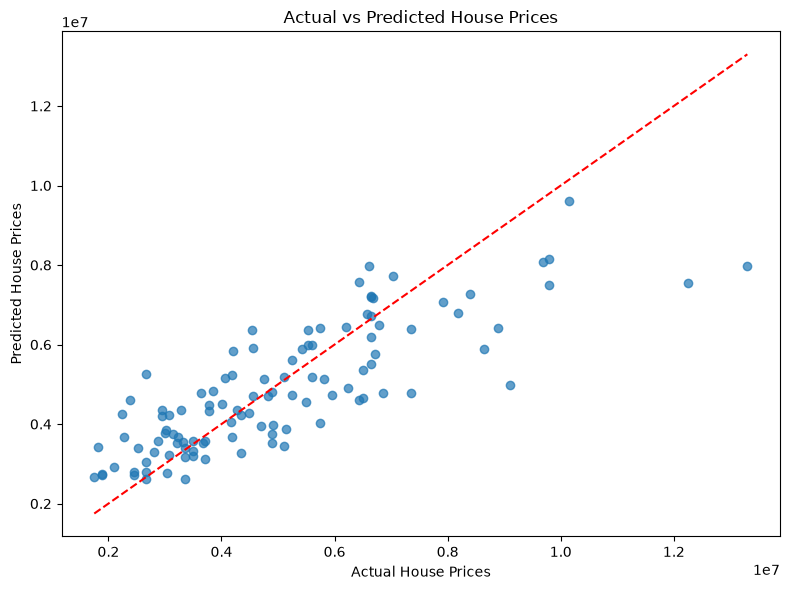

In [9]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.7)
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices")
plt.tight_layout()
plt.show()

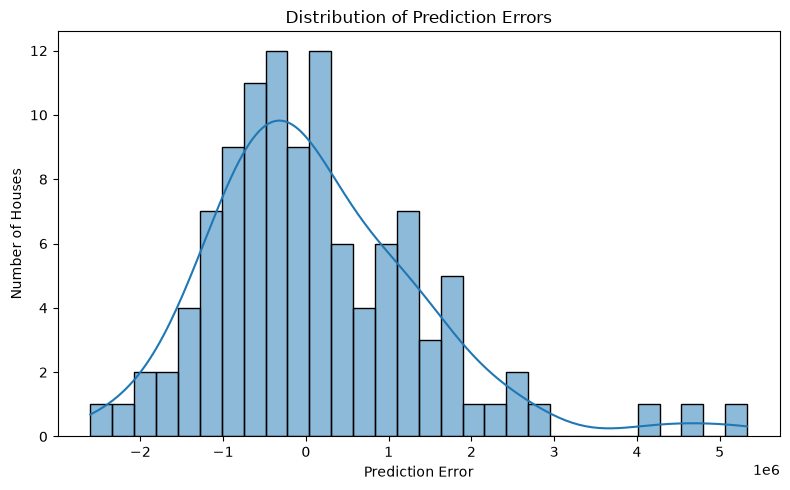

In [10]:
# Calculate prediction errors
errors = y_test - y_pred

# Plot the error distribution
plt.figure(figsize=(8, 5))
sns.histplot(errors, bins=30, kde=True)

plt.xlabel("Prediction Error")
plt.ylabel("Number of Houses")
plt.title("Distribution of Prediction Errors")
plt.tight_layout()
plt.show()

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Create and train the Random Forest model
rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

# Make predictions
rf_pred = rf_model.predict(X_test)

print("Random Forest Model Evaluation")
print("--------------------------------")
print("MAE:", round(mean_absolute_error(y_test, rf_pred), 2))
print("RMSE:", round(np.sqrt(mean_squared_error(y_test, rf_pred)), 2))
print("R² Score:", round(r2_score(y_test, rf_pred), 4))

Random Forest Model Evaluation
--------------------------------
MAE: 1021546.04
RMSE: 1400565.97
R² Score: 0.6119


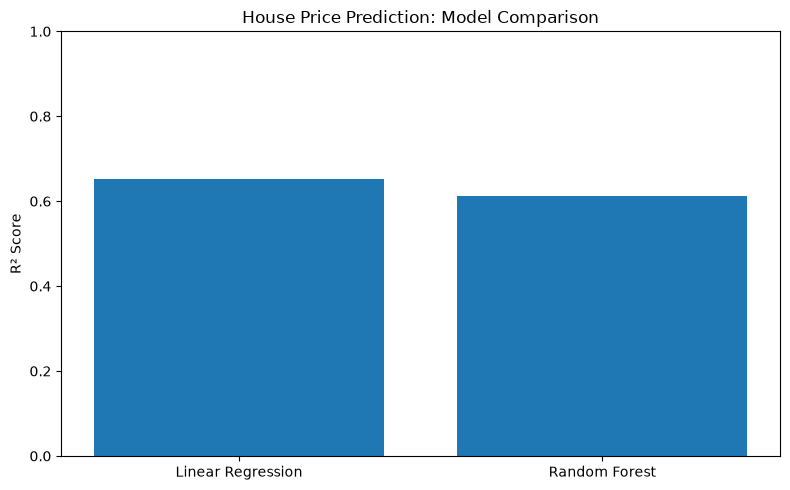

In [12]:
models = ["Linear Regression", "Random Forest"]
r2_scores = [
    r2_score(y_test, y_pred),
    r2_score(y_test, rf_pred)
]

plt.figure(figsize=(8, 5))
plt.bar(models, r2_scores)
plt.ylim(0, 1)
plt.ylabel("R² Score")
plt.title("House Price Prediction: Model Comparison")
plt.tight_layout()
plt.show()

In [13]:
# Get feature importance from Linear Regression coefficients
feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_
})

feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

print(feature_importance)

                            Feature   Coefficient  Absolute Importance
2                         bathrooms  1.094445e+06         1.094445e+06
9               airconditioning_yes  7.914267e+05         7.914267e+05
8               hotwaterheating_yes  6.846499e+05         6.846499e+05
10                     prefarea_yes  6.298906e+05         6.298906e+05
12     furnishingstatus_unfurnished -4.136451e+05         4.136451e+05
3                           stories  4.074766e+05         4.074766e+05
7                      basement_yes  3.902512e+05         3.902512e+05
5                      mainroad_yes  3.679199e+05         3.679199e+05
6                     guestroom_yes  2.316100e+05         2.316100e+05
4                           parking  2.248419e+05         2.248419e+05
11  furnishingstatus_semi-furnished -1.268818e+05         1.268818e+05
1                          bedrooms  7.677870e+04         7.677870e+04
0                              area  2.359688e+02         2.359688e+02


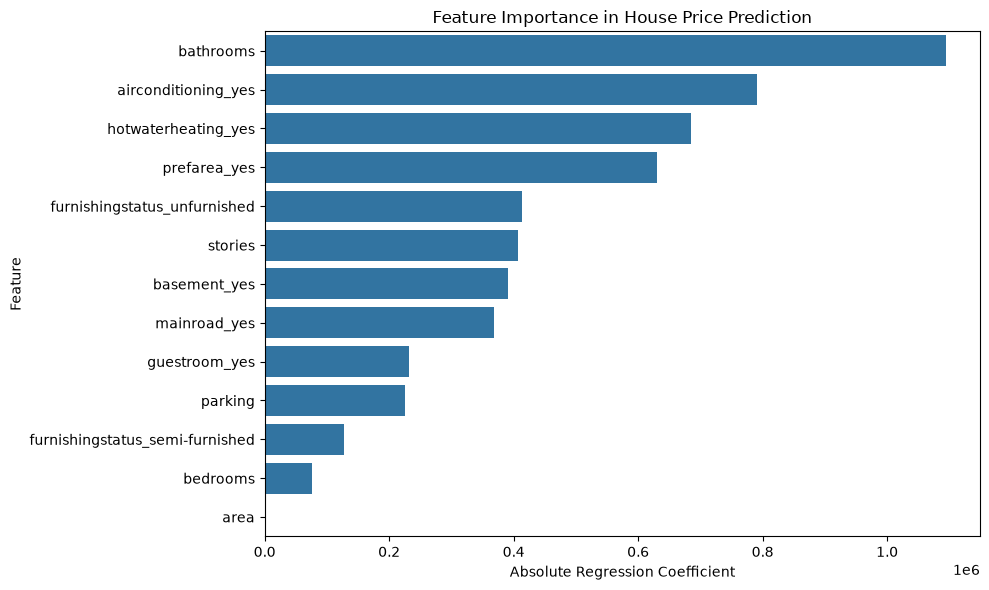

In [14]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="Absolute Importance",
    y="Feature"
)

plt.title("Feature Importance in House Price Prediction")
plt.xlabel("Absolute Regression Coefficient")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [15]:
# Create details for a sample house
new_house = pd.DataFrame([{
    "area": 5000,
    "bedrooms": 3,
    "bathrooms": 2,
    "stories": 2,
    "parking": 1,
    "mainroad_yes": 1,
    "guestroom_yes": 0,
    "basement_yes": 0,
    "hotwaterheating_yes": 0,
    "airconditioning_yes": 1,
    "prefarea_yes": 1,
    "furnishingstatus_semi-furnished": 1,
    "furnishingstatus_unfurnished": 0
}])

# Ensure the feature order matches the training data
new_house = new_house[X_train.columns]

# Predict the house price
predicted_price = model.predict(new_house)[0]

print("Sample House Details")
print("--------------------")
print("Area: 5000")
print("Bedrooms: 3")
print("Bathrooms: 2")
print("Stories: 2")
print("Parking spaces: 1")
print("Predicted House Price:", round(predicted_price, 2))

Sample House Details
--------------------
Area: 5000
Bedrooms: 3
Bathrooms: 2
Stories: 2
Parking spaces: 1
Predicted House Price: 6561252.59
